# Conway's Game of Life with Chrpypy

This notebook implements Conway's Game of Life using the `chrpypy` library.

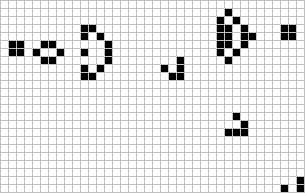

**Authors:**

Aurélien SIMON - aurelien.simon@univ-angers.fr

Vincent Barichard - vincent.barichard@univ-angers.fr


**Credits:**

Chrpypy : https://github.com/owrel/chrpypy

Chrpp : https://gitlab.com/vynce/chrpp

## Introduction to the Game of Life

John Horton Conway's Game of Life is a "zero-player game," meaning that once an initial state is defined, no further human intervention is needed; each state is calculated based on the previous state according to a set of rules. The game is played on a grid (finite or infinite), where each cell in the grid is either alive or dead. The rules for determining the state of the game `n+1` are as follows:
- A living cell remains alive if it has 2 or 3 living neighbors.
- A living cell dies of isolation if it has fewer than 2 (`<`) living neighbors.
- A living cell dies of overpopulation if it has more than 3 (`>`) living neighbors.
- A dead cell is born if it has exactly 3 living neighbors.

Let's take an example, here is an initial state:

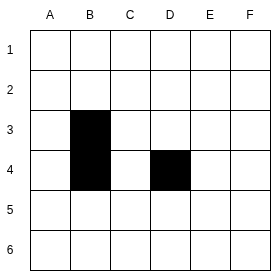

We have three living cells: at `B3`, `B4`, and `D4`. Let's focus on the dead cells `C3` and `C4`.

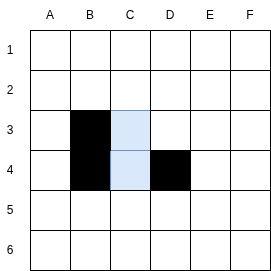

These cells each have 3 neighbors (diagonals count).
As a result, rule 4 can be applied; at the next step, these two cells will therefore be born as illustrated below.
Furthermore, cells `B3`, `B4`, and `D4`, not having enough living neighbors, respectively `1`, `1`, and `0`, will disappear.

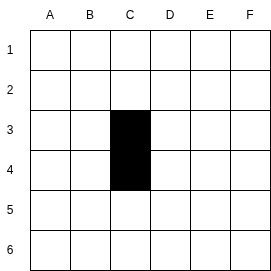

These rules, despite their simplicity, allow for the creation of different types of structures (sets of cells) with different properties; stable structures that remain in the same state from one step to another, for example:

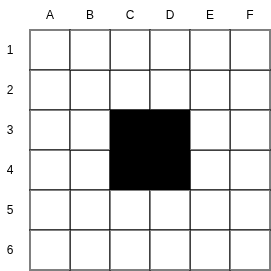

Oscillators, structures that return to their initial state after `n` steps, structures that move infinitely.
You can find video examples of different structures [here](https://www.youtube.com/watch?v=oKCDp5eiWVk).

## A few words about notebooks

A Jupyter notebook is composed of text cells or code cells that are executed one by one (with Shift + Enter or the ▶ button to the left of the cell). The crucial point to understand is that the execution order of the cells is not necessarily the order in which they appear on the screen: it is the order in which they are executed that matters. For example, if you define a variable `x = 5` in a cell at the bottom of the notebook, then use it in a cell higher up, it will still work, as long as you have executed the bottom cell first. This can create notebooks that "work" in your session but would not work if read from top to bottom.

Each executed code cell receives a number in square brackets, for example `In [3]`, which indicates the order in which it was launched. This is a good way to check that you have not executed your cells out of order. All defined variables and functions remain in memory as long as the notebook is not restarted, even if you modify or delete the cell that created them. It is of course possible to overwrite existing variables with a new assignment.

The notebook always displays the last variable of the cell in the result section. For example, if you have a cell:
```python
x = 5 + 6 * 3
x
```
The result section of the associated code cell will display `23`. In other words, when a cell is executed, a `print` is performed on the last line. So don't be surprised to see things displayed in the result section.

If you get strange results, do not hesitate to first restart your session (Runtime -> restart session).

In order not to confuse the cells of the Game of Life and the cells of the notebook, in the rest of the notebook, "notebook cell" will be mentioned to avoid confusion.

The goal of this notebook is to guide you step-by-step to create a CHR program simulating the Game of Life. This will give you an overview of how to approach and solve problems in CHR.

## Installation

In the next cell, upon execution, chrpypy will be downloaded and installed in the Python environment. This may take some time as chrpp also needs to be downloaded and compiled. On Google Collab, allow about thirty seconds (potentially shorter on your machine).

In [ ]:
!git clone https://github.com/owrel/chrpypy.git install_chrpypy && cd install_chrpypy && pip install --no-build-isolation --no-cache-dir .

fatal: destination path 'install_chrpypy' already exists and is not an empty directory.


Upon execution, the following notebook cell will verify that the installation was successful.

In [ ]:
from chrpypy import Program, Inline

# Part 1: Cells
---

As mentioned in the introduction to the Game of Life, the main element we need to work with is the cell (which we will call `cell`). We will need to represent these cells in CHR. Since these are data, we can represent them via constraints, and it is these constraints that will trigger the different rules to calculate the evolution of the grid over time.

### Why not represent the grid first?

In an imperative programming paradigm, the grid could be represented by an `n*m` matrix that would carry the state of each cell. This approach is natural because it corresponds to a data structure that is explicitly manipulated: we traverse the matrix, read, and modify each cell.

However, CHR is not an imperative paradigm but a declarative paradigm based on **constraints**. The program does not manipulate a fixed data structure that it traverses step by step; it reasons about a set of facts (the constraints present in the constraint store) and applies rewriting rules when certain patterns are recognized.

In other words, rather than starting from the global structure (the grid) to then describe the state of each cell, we start from the local element (the cell) and let the grid implicitly emerge from the set of represented cells.

### What is a cell?

According to the rules of the Game of Life, a cell can be in two states: dead or alive. Moreover, it is located in a grid and therefore has coordinates to identify it.

The coordinates can be represented by a pair of numbers `(X,Y)` while the dead or alive state can be represented by different means: a character string "dead" or "alive", two arbitrary numbers, or a boolean:
- true, the cell is alive
- false, the cell is dead

To represent cells, we will create a `cell` constraint. To do this, we first need to define a `program`. This program will carry all the necessary information for creating a CHR program.
To do this, we will call `Program` and give it a name like this:

In [ ]:
program_conway = Program(name="conway")
# la variable program_conway sera utilisé ulterieurement afin de créer des contraintes, des règles, lancer la compilation etc

In the following notebook cell, you will create the `cell` constraint. A constraint is created from a `program` via the `constraint` function like this `cell = program.constraint(...)`, the first argument of the function is the name, here "cell", and then the types of this constraint in parentheses (`(type1,type2, ...)`). In our case, two numbers (`int` in Python) and a boolean (`bool` in Python).
In the next notebook cell, create the `cell` constraint.

In [ ]:
# Ajouter ici la définition en chrpypy de la contrainte `cell`

# cell = program_conway.constraint(...)
cell = program_conway.constraint("cell", (int,int,bool))


In the following notebook cell, there is a function provided that you can use to visualize the cells in the constraint store. You can use it like this in a notebook code cell:

```python
show_cells(cell.get())
```
Which will display a grid where

- A living cell is represented by "██"
- A dead cell is represented by "░░"
- An empty space ("  ") means that no cell (neither alive nor dead) is present at that position

In [ ]:
# Visualization function: allows graphically displaying cells as a grid.
# - A living cell is represented by "██"
# - A dead cell is represented by "░░"
# - An empty space ("  ") means that no cell (neither alive nor dead) is present at that position
#
# The displayed grid is at least 7x7, for readability purposes only:
# this size does not correspond to any limit or actual size of the Game of Life grid,
# which is unbounded.

import operator
from chrpypy import Constraint

def show_cells(cells: list[Constraint]):
    min_x = min(min(cells, key=operator.itemgetter(0))[0], -3)
    min_y = min(min(cells, key=operator.itemgetter(1))[1], -3)
    max_x = max(max(cells, key=operator.itemgetter(0))[0] + 1 , 3)
    max_y = max(max(cells, key=operator.itemgetter(1))[1] + 1, 3)

    grid = [["  " for _ in range(min_x, max_x)] for _ in range(min_y, max_y)]

    for x, y, s in cells:
        if s:
            grid[y - min_y][x - min_x] = "██"
        else :
          grid[y - min_y][x - min_x] = "░░"

    width = len(grid[0])
    print(" _" + "_" * (width * 2) + "_")
    for row in grid:
        print("| " + "".join(row) + " |")
    print(" ‾" + "‾" * (width * 2) + "‾")

# The call is made in this way: show_cells(cell.store())

Now that we have our `cell` constraint and a way to visualize it, in the next cell, you will need to add (or *post* into the constraint store) some cells. To do this, you will use the `post` function of the `cell` variable like this `cell.post(...)`. The arguments must correspond to the definition of the constraint (`int` ➡ `1`,`2`,`10` ..., bool ➡ `True` or `False`). Post some dead and alive cells in the next notebook cell and then call the visualization function.

In [ ]:
# Postez ici quelques cellules vivante

cell.post(0,0,True)
cell.post(1,0,True)
cell.post(0,2,True)
cell.post(0,3,True)
cell.post(1,0,True)
cell.post(0,-2,False)
cell.post(0,-3,False)
cell.post(-1,0,False)

# Appelez ici la fonction permettant la visualisation

show_cells(cell.get())


 ______________
|       ░░     |
|       ░░     |
|              |
|     ░░████   |
|              |
|       ██     |
|       ██     |
 ‾‾‾‾‾‾‾‾‾‾‾‾‾‾


# Part 2: Adding and Removing Cells

During your `post` constraint attempts, you may have added the same constraint twice or a dead cell and an alive cell at the same position. Indeed, constraint stores can contain duplicates or, in our case, a dead cell and an alive cell at the same position.
In the next notebook cell, add dead and alive cells at the same position and then display the store's state via `print(program_conway.store())` and display the grid via `show_cells(cell.get())`.

You can "clear" the `cell` store by calling `cell.reset()`.

In [ ]:
cell.reset()

cell.post(1,1,True)
cell.post(1,1,True)
cell.post(1,1,False)

print(program_conway.store())
show_cells(cell.get())

[cell(1, 1, True), cell(1, 1, True), cell(1, 1, False)]
 ______________
|              |
|              |
|              |
|              |
|         ░░   |
|              |
 ‾‾‾‾‾‾‾‾‾‾‾‾‾‾


As shown above, the `store` can indeed store alive and dead cells, as well as multiple similar elements. To solve this problem, we will need to add rules to our program. Let's define the cases, and what we want to do when we post `cell(X,Y,S)`:

- No cell at `(X,Y)`, no rule to trigger
- A cell at `(X,Y)`, two possible cases:
  - their states are similar, in this case, remove the duplicate
  - their states are different, in this case, remove the previous element

In other words:

If `(X1,Y1) == (X2,Y2)` and `S1 == S2` then remove the duplicate (one of the two cells, whether the old or the new cell is removed, the result is identical since both are equivalent.)

If `(X1,Y1) == (X2,Y2)` and `S1 != S2` then remove the first cell

First, implement the first rule. To do this, you will need to use a `simpagation` (the `simpagation` has a two-part head; the positive and the negative, if the rule can be activated, upon activation the negative part of the head will be removed from the store).
In chrpypy, it is invoked as follows:

```python
program_conway.simpagation(
  name=...,
  negative_head=...,
  positive_head=...,
  guard=...,
  body=...,
)
```

> Depending on the rules you express, you will sometimes need to place a single element in `negative_head`, `positive_head`, or `body`, and sometimes multiple. In the first case, you simply write `body=Expression`; in the second, you use a list: `body=[Expression1, Expression2]`.


To express the different "variables" mentioned above (`X`, `Y`, `X1`, `X2`, ...), we need to declare `symbols`. A symbol represents a variable whose value is not yet known: when a rule is evaluated, CHR attempts to associate each symbol in the head of the rule with a value present in the constraints of the store. This is why they are called "matching symbols".

In chrpypy, this is done via

```python
X = program_conway.symbol("X") # for a single symbol
X, Y, Z = program_conway.symbols("X", "Y", "Z") # for multiple symbols at once
```

These symbols can be used in rules like `body=cell(X,Y,Z)`. Note that `cell(X,Y) != cell.post(X,Y)`, the first is used in rules, and the second is used to add elements to the constraint store.


Finally, for the `guard`, the `guard` being a boolean condition placed between the head and the body of a rule: if it is not satisfied, the rule does not apply. This can be added to any rule via the `guard` keyword as shown previously. A `guard` can contain one or more conditions (`condition AND condition`), in chrpypy, each condition must be in parentheses (`(X==Y)`) and separated by `&` which represents `AND` (`(X==Y) & (Y==Z)`).

Write the first rule to remove duplicates in the notebook cell below.

Don't forget to name your rules, otherwise, if you rerun a notebook cell containing an unnamed rule, it will be added again.

In [ ]:
# Écrivez ici la première règle permettant de supprimer les doublons.
X1, X2, Y1, Y2, S1, S2 = program_conway.symbols("X1","X2","Y1", "Y2", "S1","S2")

program_conway.simpagation(
    name="same_cell_same_state",
    negative_head=cell(X1,Y1,S1),
    positive_head=cell(X2,Y2,S2),
    guard=(X1 == X2) & (Y1 == Y2) & (S1 == S2),
    body=True
)


same_cell_same_state @ cell(X2, Y2, S2) \ cell(X1, Y1, S1) <=> X1 == X2 and Y1 == Y2 and S1 == S2 | success();;

As for the second part, you might be tempted to express something like:

```python
X1, X2, Y1, Y2 = program_conway.symbols("X1","X2","Y1", "Y2")

program_conway.simplification(
    name="same_cell_different_state_true_false",
    negative_head=[cell(X1,Y1,True), cell(X2,Y2,False)],
    guard=(X1 == X2) & (Y1 == Y2),
    body=cell(X2,Y2,True)
)

program_conway.simplification(
    name="same_cell_different_state_false_true",
    negative_head=[cell(X1,Y1,False), cell(X2,Y2,True)],
    guard=(X1 == X2) & (Y1 == Y2),
    body=cell(X2,Y2,False)
)
```

But this will not work. In your opinion, why is this not valid?

---

This approach is not valid because in CHR, the order of rule declaration matters: the first applicable rule will always be matched first, regardless of the order in which the constraints were posted. Thus, in the case where we have:

```python
cell.post(1,2,False)
cell.post(1,2,True)
```
or

```python
cell.post(1,2,True)
cell.post(1,2,False)
```
it will always be `same_cell_different_state_true_false` that matches first, and the living cell will therefore be systematically kept, regardless of which of the two constraints was actually posted last.

To solve this problem, it is not possible to do so without adding information, either by using a new constraint, or by adding an argument to `cell` which would be the date of addition to the store in order to compare it and determine which cell should be kept.

We will therefore introduce the following constraint:

In [ ]:
toggle = program_conway.constraint("toggle", (int, int))

The latter, when added, will declare that we want to "toggle" the cell at `(X,Y)`.

In [ ]:
X, Y = program_conway.symbols("X", "Y")
program_conway.simplification(
    name="toggle_alive",
    negative_head=[toggle(X,Y), cell(X,Y, True)],
    body = cell(X,Y,False)
)

program_conway.simplification(
    name="toggle_dead",
    negative_head=[toggle(X,Y), cell(X,Y, False)],
    body = cell(X,Y,True)
)


toggle_dead @ toggle(X, Y), cell(X, Y, false) <=> cell(X, Y, true);;

The solution is no longer to directly compare two `cell` constraints with each other, but to introduce a new intermediate constraint: `toggle(X,Y)`. Rather than posting a new cell and trying to determine, afterwards, which of the two occurrences is the most recent, we post `toggle(X,Y)` to signal the intention to change the state of the cell at `(X,Y)`. We then define two distinct rules, one for each possible state: if `toggle(X,Y)` encounters a living cell (`cell(X,Y,True)`), it replaces it with a dead cell, and vice-versa if it encounters a dead cell. The ambiguity of the previous problem disappears because there are no longer two symmetrical constraints of the same type to decide between: the head of each rule matches a precise and known state (`True` or `False`), and the body only expresses the opposite state, without needing to "guess" which of the two to keep.

So far, here is the state of your program

In [ ]:
print(program_conway.chr())

same_cell_same_state @ cell(X2, Y2, S2) \ cell(X1, Y1, S1) <=> X1 == X2 and Y1 == Y2 and S1 == S2 | success();;

toggle_alive @ toggle(X, Y), cell(X, Y, true) <=> cell(X, Y, false);;

toggle_dead @ toggle(X, Y), cell(X, Y, false) <=> cell(X, Y, true);;



### Part 3: Neighborhood

Once you have your cells, you will need to determine the number of neighbors for each cell; this number of neighbors will guide the activation of the rules (of the Game of Life). The first step of this modeling consists of adding a constraint (`count`) to your program, which will carry the number of neighbors for each cell. It can be read as "the cell at position `x,y` has `n` neighbors".

In [ ]:
# Ajouter votre contrainte ici

count = program_conway.constraint("count", (int,int,int))


To visualize the `count` constraint well, you can use the function below. Like the cell visualization function, this function displays the grid showing the number of neighbors for each cell, it can be called via
```python
show_counts(count.get())
```

In [ ]:
import operator
from chrpypy import Constraint

def show_counts(counts: list[Constraint]):
    min_x = min(min(counts, key=operator.itemgetter(0))[0], -3)
    min_y = min(min(counts, key=operator.itemgetter(1))[1], -3)
    max_x = max(max(counts, key=operator.itemgetter(0))[0] + 1 , 3)
    max_y = max(max(counts, key=operator.itemgetter(1))[1] + 1, 3)

    grid = [["  " for _ in range(min_x, max_x)] for _ in range(min_y, max_y)]

    for x, y, s in counts:
          grid[y - min_y][x - min_x] = f" {s}"

    width = len(grid[0])
    print(" _" + "_" * (width * 2) + "_")
    for row in grid:
        print("| " + "".join(row) + " |")
    print(" ‾" + "‾" * (width * 2) + "‾")

Add some `count` below and use the `show_counts` function provided

In [ ]:
# Ajoutez quelques `counts` ...
count.post(1,2,4)
count.post(1,1,1)
count.post(1,0,2)
count.post(0,2,0)

# Visualisez les `counts` ajoutés
show_counts(count.get())

 ______________
|              |
|              |
|              |
|          2   |
|          1   |
|        0 4   |
 ‾‾‾‾‾‾‾‾‾‾‾‾‾‾


Obviously, the `counts` are not yet linked to the cells. Before dealing with the counting rules, we will start by expressing the rules for moving from one grid state to another.

As explained in the introduction to the Game of Life, the rules for moving from one step to the next are:

- A living cell remains alive if it has 2 or 3 living neighbors.
- A living cell dies of isolation if it has fewer than 2 (`<`) living neighbors.
- A living cell dies of overpopulation if it has more than 3 (`>`) living neighbors.
- A dead cell is born if it has exactly 3 living neighbors.

Each of these rules will need to be modeled; to do this, follow these steps:

- What data is needed to trigger the rule (the head)?
- Should the head consume data (positive/negative head)?
- What are the activation conditions (the guard)?
- What does the rule produce (the body)?

In [ ]:
# Implement here the first rule: "A living cell remains alive if it has 2 or 3 living neighbors"
X, Y, C = program_conway.symbols("X","Y","C")

program_conway.simpagation(
    name="rule1",
    negative_head=[cell(X, Y, True), count(X, Y, C)],
    guard=((C >= 2) & (C <= 3)),
    body=cell(X, Y, True),
)

rule1 @ cell(X, Y, true), count(X, Y, C) <=> C >= 2 and C <= 3 | cell(X, Y, true);;

In [ ]:
# Implement here the second rule: "A living cell dies of isolation if it has fewer than 2 (<) living neighbors."

program_conway.simpagation(
    name="rule2",
    negative_head=[cell(X, Y, True), count(X, Y, C)],
    guard=(C < 2),
    body=cell(X, Y, False),
)

rule2 @ cell(X, Y, true), count(X, Y, C) <=> C < 2 | cell(X, Y, false);;

In [ ]:
# Implement here the third rule: "A living cell dies of overpopulation if it has more than 3 (>) living neighbors"

program_conway.simpagation(
    name="rule3",
    negative_head=[cell(X, Y, True), count(X, Y, C)],
    guard=(C > 3),
    body=cell(X, Y, False),
)

rule3 @ cell(X, Y, true), count(X, Y, C) <=> C > 3 | cell(X, Y, false);;

In [ ]:
# Implement here the fourth rule: "A dead cell is born if it has exactly 3 living neighbors"

program_conway.simpagation(
    name="rule4",
    negative_head=[cell(X, Y, False), count(X, Y, 3)],
    body=cell(X, Y, True),
)

rule4 @ cell(X, Y, false), count(X, Y, 3) <=> cell(X, Y, true);;

Finally, add a last rule, which is the default case: "A dead cell remains dead if it does not have 3 living neighbors"

In [ ]:
# Implement here the fifth rule
program_conway.simpagation(
    name="rule5",
    negative_head=[cell(X, Y, False), count(X, Y, C)],
    guard=(C != 3),
    body=cell(X, Y, False),
)

rule5 @ cell(X, Y, false), count(X, Y, C) <=> C != 3 | cell(X, Y, false);;

Now test your rules by manually posting different combinations of `cell` and `count`. Indeed, as long as no rule yet links these two constraints, it is up to you to simulate their association by posting them yourself.

You can use

In [ ]:
# test your rules here
cell.reset()
count.reset()

# Test rule1: living cell with 2 living neighbors -> remains alive
cell.post(0, 0, True)
count.post(0, 0, 2)

print(program_conway.store())

# Test rule1: living cell with 3 living neighbors -> remains alive
cell.post(1, 0, True)
count.post(1, 0, 3)

print(program_conway.store())

[cell(0, 0, True)]
[cell(0, 0, True), cell(1, 0, True)]


In [ ]:
# Test rule2: living cell with 0 living neighbor (isolation) -> dies
cell.reset()
count.reset()

cell.post(2, 0, True)
count.post(2, 0, 0)

print(program_conway.store())


# Test rule2: living cell with 1 living neighbor (isolation) -> dies
cell.post(3, 0, True)
count.post(3, 0, 1)

print(program_conway.store())

[cell(2, 0, False)]
[cell(2, 0, False), cell(3, 0, False)]


In [ ]:
# Test rule3: living cell with 4 living neighbors (overpopulation) -> dies
cell.reset()
count.reset()

cell.post(4, 0, True)
count.post(4, 0, 4)

print(program_conway.store())

[cell(4, 0, False)]


In [ ]:
# Test rule4: dead cell with exactly 3 living neighbors -> is born
cell.reset()
count.reset()

cell.post(5, 0, False)
count.post(5, 0, 3)

print(program_conway.store())

[cell(5, 0, True)]


In [ ]:
# Test rule5: dead cell with 2 living neighbors (not 3) -> remains dead
cell.reset()
count.reset()

cell.post(6, 0, False)
count.post(6, 0, 2)

print(program_conway.store())

[cell(6, 0, False)]


# Part 4: Counting

In this last modeling part, we are now going to link `cells` and `counts` by adding rules to actually count.

To build the number of living neighbors for each cell, it is not enough to consider a cell in isolation: it must be compared to all other cells on the board to determine which are its living neighbors. This is why we introduce an intermediate constraint `compute(X1,Y1,X2,Y2,E1,E2)`: it represents the comparison between two cells, the first at `(X1,Y1)` with state `E1`, the second at `(X2,Y2)` with state `E2`. In CHR, a rule can only match and reason on constraints explicitly present in its head; to "look" at the entire board and accumulate a total, we must therefore proceed two cells at a time, generating a `compute` constraint for each pair of cells to compare. It is this approach, repeated for all relevant pairs, that allows progressively building the expected count in the `count` constraint.

In the next notebook cell, add the `compute` constraint.

In [ ]:
# Ajoutez la contraintes compute ci-dessous
compute = program_conway.constraint("compute", (int,int,int,int,bool,bool))

The rule for generating the different `compute` can be done as follows:

Firstly, it is necessary to be able to compare each cell to all others: this means that the head of our rule must concern two cells at a time, we can consider that at least one of the two cells must be alive (there is no need to count dead cells among themselves).

Next, we need to ask whether these two cells should be consumed or not during the comparison. A given cell is not meant to be compared only once: it must be able to be compared to *all* its potential neighbors. If our two cells were deleted at each comparison, nothing would remain to compare for the next pairs. So, we need a head that does not alter the store.

Then comes the question of adjacency: how to express, in the `guard`, that two cells are neighbors in the sense of the Game of Life? Two cells are neighbors if they are at most one square apart, both horizontally and vertically, which translates to an absolute difference less than or equal to 1 on each of the two coordinates (in chrpypy, the absolute value is expressed as: `Inline(abs(X-Y))` where you can replace `X-Y` with the expression of your choice).

Finally, once we know that two cells are neighbors, what should the rule produce? It is not yet about counting directly, but simply about recording, for a pair of adjacent cells, the state of each of them, since it is this information that will allow, in a later rule, to determine if the compared neighbor is indeed alive and should therefore contribute to the counting.

By combining these elements; a head that does not consume the cells, a guard expressing adjacency, and a body that records the result of the comparison; you will obtain the rule allowing to generate the necessary information for counting for each pair of neighboring cells.

First, you can start by writing a rule, which takes cells two by two and produces `compute`, you can also add to the body the following expression `program.function(print, X,Y)` where `X,Y` are symbols used in the head. For example, the following rule displays the coordinates of the added `cell` in the console:
```python
program_conway.propagation(
  positive_head=cell(X,Y,True),
  body=program_conway.function(print, X,Y)
)
```

In [ ]:
# Write your test rules here:

program_conway.propagation(
    name="compute",
    positive_head=[cell(X1, Y1, True), cell(X2, Y2, S2)],
    guard=((Inline("abs(X1-X2)") <= 1) & (Inline("abs(Y1-Y2)") <= 1)),
    body=compute(X1, Y1, X2, Y2, True, S2),
)

compute @ cell(X1, Y1, true), cell(X2, Y2, S2) ==> abs(X1-X2) <= 1 and abs(Y1-Y2) <= 1 | compute(X1, Y1, X2, Y2, true, S2);;

In [ ]:
# Test: two adjacent living cells -> compute must be generated
cell.reset()
compute.reset()
cell.post(0, 0, True)
cell.post(1, 0, True)
print(compute.get())

[compute(1, 0, 0, 0, True, True)]


In [ ]:
# Test: an adjacent living and dead cell -> compute must be generated with S2=False
cell.reset()
compute.reset()
cell.post(2, 0, True)
cell.post(3, 0, False)
print(compute.get())

[compute(2, 0, 3, 0, True, False)]


In [ ]:
# Test: diagonal (adjacency in X and Y)
cell.reset()
compute.reset()
cell.post(0, 5, True)
cell.post(1, 6, True)
print(compute.get())

[compute(1, 6, 0, 5, True, True)]


In [ ]:
# Test: non-adjacent cells -> no compute should be generated
cell.reset()
compute.reset()
cell.post(0, 10, True)
cell.post(5, 10, True)
print(compute.get())

[]


In [ ]:
# Test: three living cells, all close -> 3 computes expected
cell.reset()
compute.reset()
cell.post(10, 10, True)
cell.post(11, 10, True)
cell.post(10, 11, True)
print(compute.get())

[compute(11, 10, 10, 10, True, True), compute(10, 11, 11, 10, True, True), compute(10, 11, 10, 10, True, True)]


Now that we have `compute(X1,Y1,X2,Y2,E1,E2)` for each pair of neighboring cells, we need to use it to truly increment the counters. The `compute` constraint encodes four possible cases depending on the states `E1` and `E2` of the two compared cells: alive/alive, alive/dead, dead/alive, and dead/dead. However, only a *living* neighbor should contribute to a cell's count; the state of the cell itself (alive or dead) is irrelevant for its own counter, only that of its neighbor matters.

Therefore, we need to treat each of these four cases separately: when both cells are alive, each is a living neighbor of the other, so both counters must be incremented. When only one of the two is alive, only the counter of the *dead or alive* cell whose neighbor is alive should be incremented; the counter of the living cell has no reason to be incremented since its neighbor is dead. Finally, when both cells are dead, no counting is necessary; the `compute` constraint can simply be consumed without producing anything.

Once this reasoning is broken down case by case, all that remains is to translate each into a rule: the head consumes the corresponding `compute` as well as the relevant `count`(s), and the body republishes these `count` constraints with their value incremented by 1 when necessary.

For reasons that will be explained in the next section, you should use an alternative `count` constraint named `count_` instead of `count` directly. You can already ask yourself why you need to use an alternative `count`.

Be careful, however: to increment a counter, there must be one to consume in the head of the rule. In other words, a rule like "I consume `count(X,Y,C)` and I republish `count(X,Y,C+1)`" can only be triggered if a `count` already exists for that cell. Therefore, even before any counting rule can execute, a basic counter must be present in the store for each cell. Also add a rule that initializes `count_(X,Y,0)` each time a `cell` is added.

In the following notebook cells, write the rules corresponding to each case; a set of tests is provided.

In [ ]:
count_ = program_conway.constraint("count_", (int,int,int))

# write the rules here:

X1, Y1, X2, Y2, C1, C2, S = program_conway.symbols("X1", "Y1", "X2", "Y2", "C1", "C2", "S")

program_conway.propagation(
    positive_head = cell(X,Y,S),
    body = count_(X,Y,0)
)

program_conway.simplification(
    name = "count_alive_alive",
    negative_head=[
        compute(X1, Y1, X2, Y2, True, True),
        count_(X1, Y1, C1),
        count_(X2, Y2, C2),
    ],
    body=[count_(X1, Y1, C1 + 1), count_(X2, Y2, C2 + 1)],
)

program_conway.simplification(
    name="count_alive_dead",
    negative_head=[
        compute(X1, Y1, X2, Y2, True, False),
        count_(X2, Y2, C2),
    ],
    body=[count_(X2, Y2, C2 + 1)],
)

program_conway.simplification(
    name="count_false_true",
    negative_head=[
        compute(X1, Y1, X2, Y2, False, True),
        count_(X1, Y1, C1),
    ],
    body=[count_(X1, Y1, C1 + 1)],
)

program_conway.simplification(
    name="count_false_false",
    negative_head=[
        compute(X1, Y1, X2, Y2, False, False),
    ],
)

count_false_false @ compute(X1, Y1, X2, Y2, false, false) <=> success();;

In [ ]:
# Test 1: two horizontally adjacent living cells
cell.reset()
count_.reset()
cell.post(0, 0, True)
cell.post(1, 0, True)
cell.post(0, 1, False)
cell.post(1, 1, False)


print(program_conway.store())
show_cells(cell.get())
show_counts(count_.get())

[cell(0, 1, False), cell(1, 1, False), cell(0, 0, True), cell(1, 0, True), count_(0, 1, 2), count_(1, 1, 2), count_(1, 0, 1), count_(0, 0, 1)]
 ______________
|              |
|              |
|              |
|       ████   |
|       ░░░░   |
|              |
 ‾‾‾‾‾‾‾‾‾‾‾‾‾‾
 ______________
|              |
|              |
|              |
|        1 1   |
|        2 2   |
|              |
 ‾‾‾‾‾‾‾‾‾‾‾‾‾‾


In [ ]:
# Test 2: a 2x2 block of living cells (each cell has 3 living neighbors)
cell.reset()
count_.reset()
cell.post(0, 0, True)
cell.post(1, 0, True)
cell.post(0, 1, True)
cell.post(1, 1, True)


show_cells(cell.get())
show_counts(count_.get())

 ______________
|              |
|              |
|              |
|       ████   |
|       ████   |
|              |
 ‾‾‾‾‾‾‾‾‾‾‾‾‾‾
 ______________
|              |
|              |
|              |
|        3 3   |
|        3 3   |
|              |
 ‾‾‾‾‾‾‾‾‾‾‾‾‾‾


# Part 5: Controlling Rule Activation

In the previous example, you may have noticed two things:
- we used an alternative `count`
- the `count` values are initialized to 0

Try to ask yourself why we had to proceed this way to test the rules.

---

This is because in CHR, as soon as an element is added to the store, all applicable rules execute immediately. Thus, at the slightest `cell.post(1,2,True)`, the concerned rules trigger immediately: this cell would die, for lack of neighbors, even before the other cells have had the opportunity to be posted. Indeed, rules trigger with each addition, regardless of whether other cells are added right after.

We therefore need a way to control *when* rules should execute, rather than letting them trigger immediately with each `post`.

To do this, we can add a safeguard via an `action` constraint, carrying a string representing the current action. The idea is that each rule will now have to include `action` in its head, in addition to its own constraints: the rule will thus only be able to trigger if the action currently present in the store corresponds to the expected one.

Several possibilities exist for breaking down these actions, but the simplest is to rely on the rules we have already written, following the successive steps of a Game of Life generation:

- a state without action, the base state: allows the user to add cells and control whether they are alive or dead (`toggle`)
- action `"init"`: initializes the counter of each `cell` to 0
- action `"compute"`: allows generating the `compute` constraints
- action `"count"`: allows triggering the rules related to counting neighbors
- action `"next_gen"`: allows calculating the next grid state

Thus, rewrite all the Game of Life rules in a new chrpypy program, incorporating actions into each rule. Between each state, remember to remove the previous action and move to the new one. Also, be careful, some rules will switch to simpagation (so as not to consume the current action).
Don't forget to change `count_` to `count`.

In [ ]:
# final version of the game of life
conway_final = Program(name="game_of_life")

cell = conway_final.constraint("cell", (int, int, bool))
count = conway_final.constraint("count", (int, int, int))
compute = conway_final.constraint("compute", (int, int, int, int, bool, bool))
action = conway_final.constraint("action", (str,))
toggle = conway_final.constraint("toggle", (int, int))


# Position
X = conway_final.symbol("X")
Y = conway_final.symbol("Y")
X1 = conway_final.symbol("X1")
Y1 = conway_final.symbol("Y1")
X2 = conway_final.symbol("X2")
Y2 = conway_final.symbol("Y2")

# Count
C = conway_final.symbol("C")
C1 = conway_final.symbol("C1")
C2 = conway_final.symbol("C2")


# State
S1 = conway_final.symbol("S1")
S2 = conway_final.symbol("S2")
S = conway_final.symbol("S")


conway_final.simplification(
    name="toggle_alive",
    negative_head=[toggle(X, Y), cell(X, Y, True)],
    body=cell(X, Y, False)
)

conway_final.simplification(
    name="toggle_dead",
    negative_head=[toggle(X, Y), cell(X, Y, False)],
    body=cell(X, Y, True)
)


conway_final.simpagation(
    name="deduplication",
    negative_head=cell(X1, Y1, S1),
    positive_head=cell(X2, Y2, S2),
    guard=(X1 == X2) & (Y1 == Y2) & (S1 == S2),
    body=True
)


# Count state
conway_final.propagation(
    name="init_count",
    positive_head=[action("init"), cell(X, Y, S)],
    body=count(X, Y, 0),
)

conway_final.simplification(
    name="init_to_compute",
    negative_head=action("init"),
    body=action("compute"),
)

conway_final.propagation(
    name="compute_neighbours",
    positive_head=[action("compute"), cell(X1, Y1, True), cell(X2, Y2, S2)],
    guard=((Inline("abs(X1-X2)") <= 1) & (Inline("abs(Y1-Y2)") <= 1)),
    body=compute(X1, Y1, X2, Y2, True, S2),
)

conway_final.simplification(
    name="compute_to_count",
    negative_head=action("compute"),
    body=action("count"),
)

conway_final.simpagation(
    name="count_alive_alive",
    positive_head=action("count"),
    negative_head=[
        compute(X1, Y1, X2, Y2, True, True),
        count(X1, Y1, C1),
        count(X2, Y2, C2),
    ],
    body=[count(X1, Y1, C1 + 1), count(X2, Y2, C2 + 1)],
)

conway_final.simpagation(
    name="count_alive_dead",
    positive_head=action("count"),
    negative_head=[
        compute(X1, Y1, X2, Y2, True, False),
        count(X2, Y2, C2),
    ],
    body=[count(X2, Y2, C2 + 1)],
)

conway_final.simpagation(
    name="count_dead_alive",
    positive_head=action("count"),
    negative_head=[
        compute(X1, Y1, X2, Y2, False, True),
        count(X1, Y1, C1),
    ],
    body=[count(X1, Y1, C1 + 1)],
)

conway_final.simpagation(
    name="count_dead_dead",
    positive_head=action("count"),
    negative_head=[
        compute(X1, Y1, X2, Y2, False, False),
    ],
)

conway_final.simplification(
    name="count_to_next_gen",
    negative_head=action("count"),
    body=action("next_gen"),
)

conway_final.simpagation(
    name="alive_dies_isolation_or_overpopulation",
    positive_head=action("next_gen"),
    negative_head=[cell(X, Y, True), count(X, Y, C)],
    guard=(C <= 1) | (C > 3),
    body=cell(X, Y, False),
)

conway_final.simpagation(
    name="alive_survives",
    positive_head=action("next_gen"),
    negative_head=[cell(X, Y, True), count(X, Y, C)],
    guard=((C >= 2) & (C <= 3)),
    body=cell(X, Y, True),
)

conway_final.simpagation(
    name="dead_becomes_alive",
    positive_head=action("next_gen"),
    negative_head=[cell(X, Y, False), count(X, Y, 3)],
    body=cell(X, Y, True),
)

conway_final.simpagation(
    name="dead_stays_dead",
    positive_head=action("next_gen"),
    negative_head=[cell(X, Y, False), count(X, Y, C)],
    guard=(C != 3),
    body=cell(X, Y, False),
)


print(conway_final.chr())

toggle_alive @ toggle(X, Y), cell(X, Y, true) <=> cell(X, Y, false);;

toggle_dead @ toggle(X, Y), cell(X, Y, false) <=> cell(X, Y, true);;

deduplication @ cell(X2, Y2, S2) \ cell(X1, Y1, S1) <=> X1 == X2 and Y1 == Y2 and S1 == S2 | success();;

init_count @ action("init"), cell(X, Y, S) ==> count(X, Y, 0);;

init_to_compute @ action("init") <=> action("compute");;

compute_neighbours @ action("compute"), cell(X1, Y1, true), cell(X2, Y2, S2) ==> abs(X1-X2) <= 1 and abs(Y1-Y2) <= 1 | compute(X1, Y1, X2, Y2, true, S2);;

compute_to_count @ action("compute") <=> action("count");;

count_alive_alive @ action("count") \ compute(X1, Y1, X2, Y2, true, true), count(X1, Y1, C1), count(X2, Y2, C2) <=> count(X1, Y1, (C1 + 1)), count(X2, Y2, (C2 + 1));;

count_alive_dead @ action("count") \ compute(X1, Y1, X2, Y2, true, false), count(X2, Y2, C2) <=> count(X2, Y2, (C2 + 1));;

count_dead_alive @ action("count") \ compute(X1, Y1, X2, Y2, false, true), count(X1, Y1, C1) <=> count(X1, Y1, (C1 + 1));;

In [ ]:
# # Test the final program
# cell.reset()
# # Initialize the grid: all cells dead
# for i in range(-5, 5):
#     for j in range(-5, 5):
#         cell.post(i, j, False)

# # Place a glider via toggle
# glider_cells = [
#     (0, -1),
#     (1, 0),
#     (-1, 1),
#     (0, 1),
#     (1, 1),
# ]

# for x, y in glider_cells:
#     toggle.post(x, y)

# show_cells(cell.get())
# action.post("init")
# show_cells(cell.get())
# action.post("init")
# show_cells(cell.get())
# action.post("init")
# show_cells(cell.get())
# action.post("init")
# show_cells(cell.get())

In [ ]:
# !pip install ipywidgets IPython numpy

In [ ]:
# import numpy as np
# from ipywidgets import Button, GridBox, Output, HBox, VBox
# from IPython.display import display, clear_output
# from functools import partial
# from time import sleep

# grid_size = 25
# squares = []
# button_size = "20px"
# cell.reset()

# for i in range(grid_size):
#     for j in range(grid_size):
#         cell.post(i, j, False)

# def on_square_click(x, y, b):
#     with output:
#         clear_output()
#         toggle.post(x, y)
#         update_grid_display()

# for i in range(grid_size):
#     for j in range(grid_size):
#         square = Button(
#             description="",
#             disabled=False,
#             button_style="",
#             style={"button_color": "white"},
#             layout={"width": button_size, "height": button_size, "border": "1px solid gray"}
#         )
#         square.on_click(partial(on_square_click, i, j))
#         squares.append(square)

# grid_box = GridBox(
#     children=squares,
#     layout={
#         "grid_template_columns": f"repeat({grid_size}, {button_size})",
#         "grid_auto_rows": button_size,
#         "grid_gap": "0px",
#         "width": "fit-content",
#         "height": "fit-content",
#     }
# )

# next_step_button = Button(
#     description="Next Step",
#     button_style="success",
#     icon="step-forward"
# )

# next50_step_button = Button(
#     description="50 Next Steps",
#     button_style="success",
#     icon="step-forward"
# )

# reset_button = Button(
#     description="Reset",
#     button_style="success",
#     icon="step-forward"
# )

# output = Output()

# def update_grid_display():
#     current_cells = [(x, y) for x, y, s in cell.get() if s]
#     for i in range(grid_size):
#         for j in range(grid_size):
#             idx = i * grid_size + j
#             squares[idx].style.button_color = "black" if (i, j) in current_cells else "white"

# def next_generation(b):
#     with output:
#         clear_output()
#         action.post("init")
#         update_grid_display()

# def next_50_generation(b):
#     with output:
#         for _ in range(50):
#             clear_output()
#             action.post("init")
#             update_grid_display()
#             sleep(0.1)

# def reset_grid(b):
#     with output:
#         clear_output()
#         cell.reset()
#         count.reset()
#         compute.reset()
#         action.reset()
#         for i in range(grid_size):
#             for j in range(grid_size):
#                 cell.post(i, j, False)
#         action.post("idle")
#         update_grid_display()


# next_step_button.on_click(next_generation)
# next50_step_button.on_click(next_50_generation)
# reset_button.on_click(reset_grid)

In [ ]:
# display(VBox([grid_box, next_step_button, next50_step_button, reset_button, output]))

# update_grid_display()